In [ ]:
# Step 0 - Import Libraries and File Names
import pandas as pd
import matplotlib.pyplot as plt

POSTLINKS_FILE = r"D:\\ict\\sem5\\ML\\LHC\\LHC1\\Arjun_Assignment_data-20220427T165022Z-002\\Arjun_Assignment_data\dataset-20210607T020316Z-001\\dataset\\postLinks.csv"
POSTS_FILE = r"D:\\ict\sem5\\ML\\LHC\\LHC1\\Arjun_Assignment_data-20220427T165022Z-002\\Arjun_Assignment_data\\dataset-20210607T020316Z-001\dataset\\posts_short.csv"
USERS_FILE = r"D:\\ict\\sem5\\ML\\LHC\\LHC1\\Arjun_Assignment_data-20220427T165022Z-002\\Arjun_Assignment_data\\dataset-20210607T020316Z-002\\dataset\\users.csv"


In [ ]:
# Step 1 - Load the Data
postlinks = pd.read_csv(POSTLINKS_FILE, usecols=["post_id", "related_post_id", "link_type_id", "creation_date"])
posts = pd.read_csv(POSTS_FILE, usecols=["id", "post_type_id", "creation_date", "owner_user_id", "tags"])
users = pd.read_csv(USERS_FILE, usecols=["id", "reputation"])

users = users.rename(columns={"id": "owner_user_id"})

questions = posts[posts["post_type_id"] == 1].copy()
questions["creation_date"] = pd.to_datetime(questions["creation_date"], errors="coerce")

print("Total questions:", len(questions))

Total questions: 676204


In [ ]:
# Step 2 - Find Duplicate Questions
duplicate_ids = postlinks[postlinks["link_type_id"] == 3]["post_id"]

questions["is_duplicate"] = questions["id"].isin(duplicate_ids)

print("Duplicate questions:", questions["is_duplicate"].sum())
print("Normal questions   :", (~questions["is_duplicate"]).sum())

Duplicate questions: 399974
Normal questions   : 276230


In [ ]:
# Step 3 - Split Tags and Count Them
questions["tag_list"] = questions["tags"].fillna("").str.findall("<([^>]+)>")

all_tags = questions["tag_list"].explode()
tag_counts = all_tags.value_counts()

print("Total tag uses:", all_tags.count())
print("Unique tags   :", len(tag_counts))

Total tag uses: 1921047
Unique tags   : 25310


num_tags
1     94523
2    189704
3    194334
4    124127
5     73490
6        26
Name: count, dtype: int64
Average tags per question: 2.84


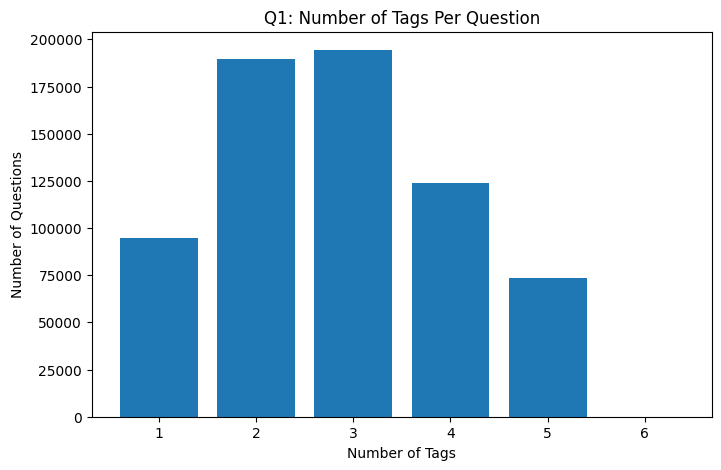

In [ ]:
# Q1 - Number of Tags Per Question
questions["num_tags"] = questions["tag_list"].apply(len)
tags_per_question = questions["num_tags"].value_counts().sort_index()

print(tags_per_question)
print("Average tags per question:", round(questions["num_tags"].mean(), 2))

plt.figure(figsize=(8, 5))
plt.bar(tags_per_question.index, tags_per_question.values)
plt.title("Q1: Number of Tags Per Question")
plt.xlabel("Number of Tags")
plt.ylabel("Number of Questions")
plt.show()

In [ ]:
# Q2 - Total Number of Unique Tags
print("Total unique tags:", len(tag_counts))

Total unique tags: 25310


tag_list
java           94846
javascript     81346
php            65333
c#             61899
python         61505
c++            40158
android        39910
html           33736
jquery         32601
mysql          24765
css            23161
c              22166
ios            21583
arrays         19867
r              19744
sql            17227
.net           14290
regex          14107
string         13397
objective-c    12949
swift          11197
json           10705
iphone          9295
asp.net         8276
sql-server      8165
Name: count, dtype: int64


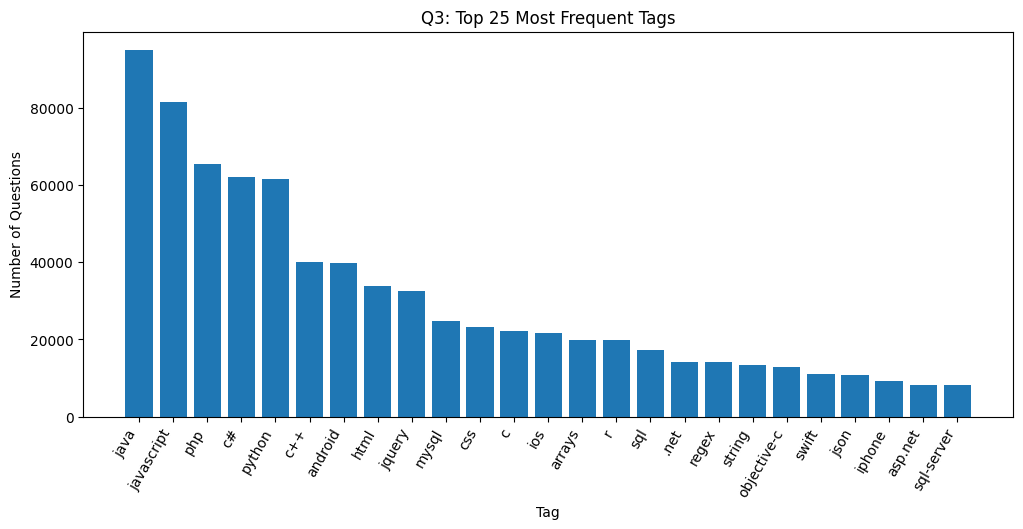

In [ ]:
# Q3 - Top 25 Most Frequent Tags
top25 = tag_counts.head(25)
print(top25)

plt.figure(figsize=(12, 5))
plt.bar(top25.index, top25.values)
plt.title("Q3: Top 25 Most Frequent Tags")
plt.xlabel("Tag")
plt.ylabel("Number of Questions")
plt.xticks(rotation=60, ha="right")
plt.show()

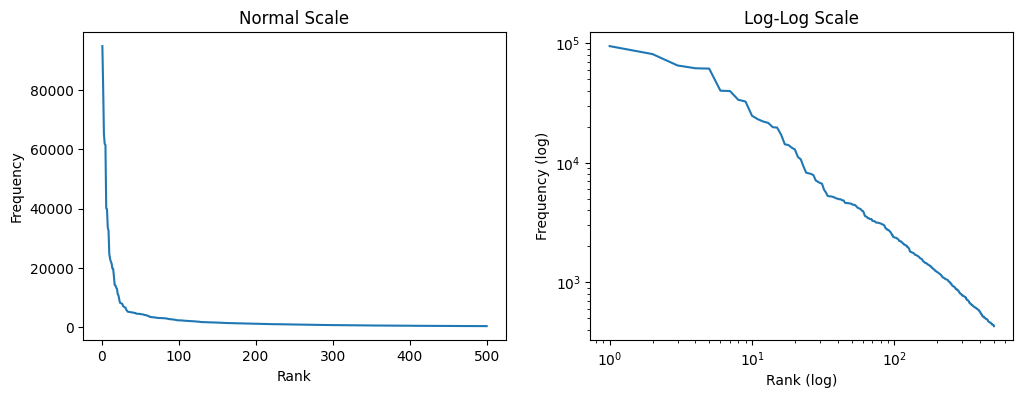

In [ ]:
# Q4 - Distribution of Top 500 Tags
top500 = tag_counts.head(500).values
ranks = list(range(1, 501))

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(ranks, top500)
plt.title("Normal Scale")
plt.xlabel("Rank")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.plot(ranks, top500)
plt.xscale("log")
plt.yscale("log")
plt.title("Log-Log Scale")
plt.xlabel("Rank (log)")
plt.ylabel("Frequency (log)")

plt.show()

Highest ratio: 98.32 %
Average ratio: 50.23 %


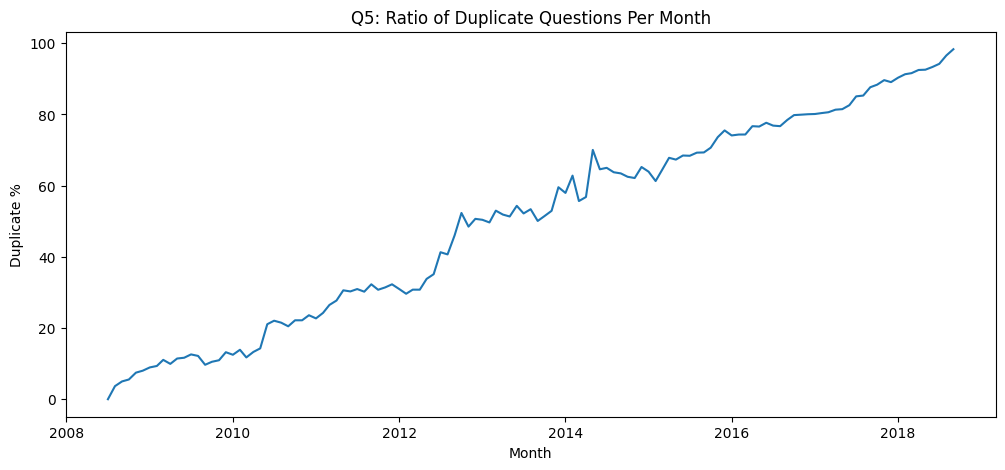

In [ ]:
# Q5 - Ratio of Duplicate Questions Per Month (2008 to 2018)
years = questions["creation_date"].dt.year
selected = questions[(years >= 2008) & (years <= 2018)]

month = selected["creation_date"].dt.to_period("M")
monthly_ratio = selected.groupby(month)["is_duplicate"].mean() * 100

print("Highest ratio:", round(monthly_ratio.max(), 2), "%")
print("Average ratio:", round(monthly_ratio.mean(), 2), "%")

plt.figure(figsize=(12, 5))
plt.plot(monthly_ratio.index.to_timestamp(), monthly_ratio.values)
plt.title("Q5: Ratio of Duplicate Questions Per Month")
plt.xlabel("Month")
plt.ylabel("Duplicate %")
plt.show()

                        count  dup_percent
tag_list                                  
nullreferenceexception    505    94.059406
lnk2019                    94    92.553191
mongoose-schema            80    92.500000
tidyverse                  87    91.954023
cannot-find-symbol         60    91.666667
undefined-index            59    91.525424
contact-form               99    89.898990
nullpointerexception     2373    89.422672
data-cleaning              55    89.090909
axios                      91    85.714286
mean-stack                 66    84.848485
es6-class                  81    83.950617
python-3.6                183    83.060109
codeigniter-3              80    82.500000
jsf-2.2                   211    82.464455
contact                   106    82.075472
data-science               60    81.666667
angular5                   86    81.395349
server                    342    80.994152
mariadb                   156    80.769231


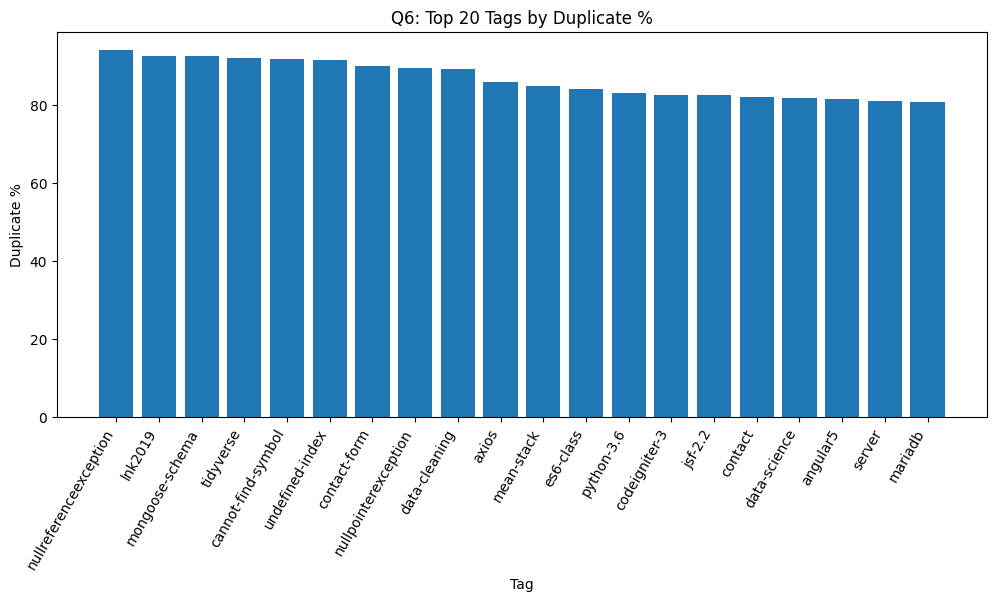

In [ ]:
# Q6 - Top 20 Tags With Highest % of Duplicate Questions
tag_table = questions[["tag_list", "is_duplicate"]].explode("tag_list")

stats = tag_table.groupby("tag_list")["is_duplicate"].agg(["count", "mean"])
MIN_QUESTIONS = 50
stats = stats[stats["count"] >= MIN_QUESTIONS]
stats["dup_percent"] = stats["mean"] * 100

top20 = stats.sort_values("dup_percent", ascending=False).head(20)
print(top20[["count", "dup_percent"]])

plt.figure(figsize=(12, 5))
plt.bar(top20.index, top20["dup_percent"])
plt.title("Q6: Top 20 Tags by Duplicate %")
plt.xlabel("Tag")
plt.ylabel("Duplicate %")
plt.xticks(rotation=60, ha="right")
plt.show()

Average days to close: 125.1
Median days to close : 0.1
time_group
< 1 day        284900
1-7 days        22754
1-4 weeks        9465
1-6 months      22912
6-12 months     14473
> 1 year        45470
Name: count, dtype: int64


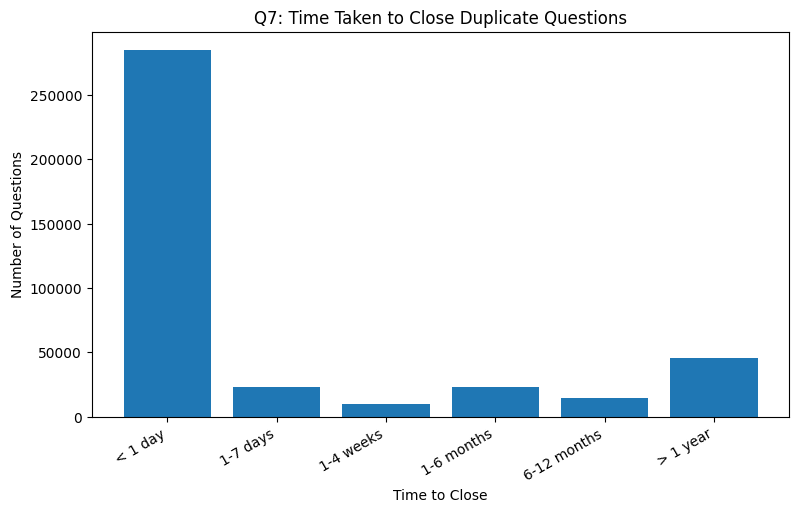

In [ ]:
# Q7 - Time Taken to Close Duplicate Questions
dup_links = postlinks[postlinks["link_type_id"] == 3].copy()
dup_links["link_date"] = pd.to_datetime(dup_links["creation_date"], errors="coerce")
dup_links = dup_links.groupby("post_id")["link_date"].min().reset_index()

dups = questions[questions["is_duplicate"]][["id", "creation_date"]]
dups = dups.rename(columns={"id": "post_id", "creation_date": "asked_date"})

merged = dups.merge(dup_links, on="post_id")
merged["days_to_close"] = (merged["link_date"] - merged["asked_date"]).dt.total_seconds() / 86400
merged = merged[merged["days_to_close"] >= 0]

print("Average days to close:", round(merged["days_to_close"].mean(), 1))
print("Median days to close :", round(merged["days_to_close"].median(), 1))

bins = [0, 1, 7, 30, 180, 365, float("inf")]
labels = ["< 1 day", "1-7 days", "1-4 weeks", "1-6 months", "6-12 months", "> 1 year"]
merged["time_group"] = pd.cut(merged["days_to_close"], bins=bins, labels=labels, right=False)
time_counts = merged["time_group"].value_counts().sort_index()
print(time_counts)

plt.figure(figsize=(9, 5))
plt.bar(time_counts.index, time_counts.values)
plt.title("Q7: Time Taken to Close Duplicate Questions")
plt.xlabel("Time to Close")
plt.ylabel("Number of Questions")
plt.xticks(rotation=30, ha="right")
plt.show()

rep_group
0-9        72056
10-49      70929
50-99      29244
100-499    53971
500-999    20820
1K-5K      27629
5K-10K      5229
10K-50K     4097
50K+         636
Name: count, dtype: int64
Users with reputation below 100: 60.5 %


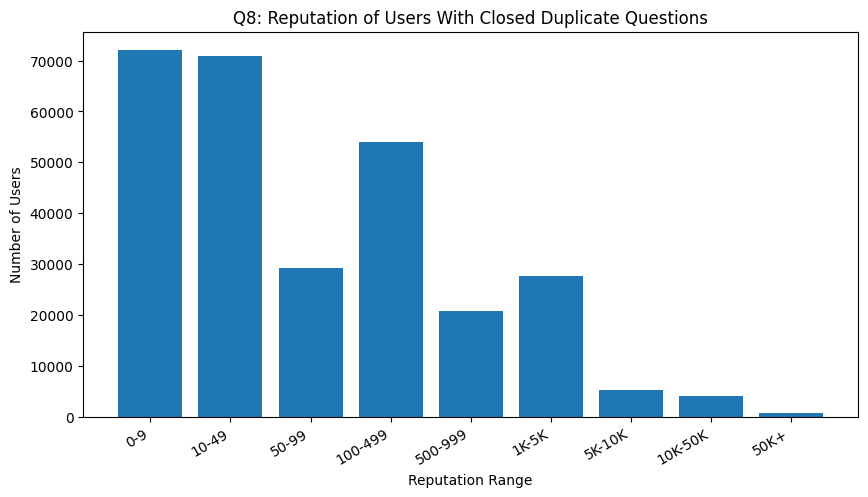

In [ ]:
# Q8 - Reputation of Users Whose Questions Were Closed as Duplicates
dup_questions = questions[questions["is_duplicate"]]
dup_users = dup_questions.merge(users, on="owner_user_id")
dup_users = dup_users.drop_duplicates("owner_user_id")

bins = [0, 10, 50, 100, 500, 1000, 5000, 10000, 50000, float("inf")]
labels = ["0-9", "10-49", "50-99", "100-499", "500-999", "1K-5K", "5K-10K", "10K-50K", "50K+"]
dup_users["rep_group"] = pd.cut(dup_users["reputation"], bins=bins, labels=labels, right=False)
rep_counts = dup_users["rep_group"].value_counts().sort_index()
print(rep_counts)

low_percent = (dup_users["reputation"] < 100).mean() * 100
print("Users with reputation below 100:", round(low_percent, 1), "%")

plt.figure(figsize=(10, 5))
plt.bar(rep_counts.index, rep_counts.values)
plt.title("Q8: Reputation of Users With Closed Duplicate Questions")
plt.xlabel("Reputation Range")
plt.ylabel("Number of Users")
plt.xticks(rotation=30, ha="right")
plt.show()

In [ ]:
# Q9 - % of Questions Covered by Top 500 Tags
tag_table2 = questions[["id", "tag_list"]].explode("tag_list").dropna()

top500_names = tag_counts.head(500).index
covered_500 = tag_table2[tag_table2["tag_list"].isin(top500_names)]["id"].nunique()
percent_500 = covered_500 / len(questions) * 100

print("Total questions     :", len(questions))
print("Covered by top 500  :", covered_500)
print("Coverage            :", round(percent_500, 2), "%")

not_covered_ids = tag_table2[~tag_table2["tag_list"].isin(top500_names)]["id"].nunique()
all_covered_500 = tag_table2["id"].nunique() - not_covered_ids
print("All tags in top 500 :", round(all_covered_500 / len(questions) * 100, 2), "%")

Total questions     : 676204
Covered by top 500  : 662549
Coverage            : 97.98 %
All tags in top 500 : 52.11 %


Covered by top 5000 : 675145
Coverage            : 99.84 %
Extra coverage      : 1.86 %
All tags in top 5000: 88.48 %


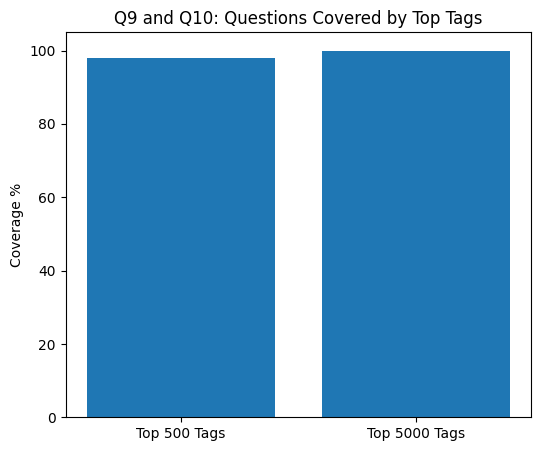

In [ ]:
# Q10 - % of Questions Covered by Top 5000 Tags
top5000_names = tag_counts.head(5000).index
covered_5000 = tag_table2[tag_table2["tag_list"].isin(top5000_names)]["id"].nunique()
percent_5000 = covered_5000 / len(questions) * 100

print("Covered by top 5000 :", covered_5000)
print("Coverage            :", round(percent_5000, 2), "%")
print("Extra coverage      :", round(percent_5000 - percent_500, 2), "%")

not_covered_ids = tag_table2[~tag_table2["tag_list"].isin(top5000_names)]["id"].nunique()
all_covered_5000 = tag_table2["id"].nunique() - not_covered_ids
print("All tags in top 5000:", round(all_covered_5000 / len(questions) * 100, 2), "%")

plt.figure(figsize=(6, 5))
plt.bar(["Top 500 Tags", "Top 5000 Tags"], [percent_500, percent_5000])
plt.title("Q9 and Q10: Questions Covered by Top Tags")
plt.ylabel("Coverage %")
plt.ylim(0, 105)
plt.show()